# Project 1 — Bank Marketing: Predicting Term-Deposit Subscription

**Course:** DSC8307 Data Mining, Modeling and Analytics

**Student name:** NAMUYOMBA NAKACHWA EMILLY  
**Registration number:** S25M19/047  
**Access number:** B35963


## Executive Summary
This notebook details a comprehensive machine learning pipeline designed to predict customer subscription behavior for bank term deposits based on direct marketing campaign data. By adhering to the Knowledge Discovery in Databases (KDD) framework, this project covers rigorous problem formulation, exploratory data analysis (EDA), data cleaning, feature engineering, imbalanced classification modeling, threshold tuning, and model interpretability using SHAP/feature importances. The resulting probabilistic ranker minimizes telemarketing campaign overhead while maximizing subscription uptake.


## Problem Formulation. 
**Business problem.** A Portuguese bank sold term deposits through telephone campaigns. Each call costs agent time and may annoy the customer, and only about 1 in 9 people called subscribed. The bank wants to **rank customers by how likely they are to subscribe**, so that future campaigns call the most promising people first.

** Problem Formulation Business Context. **
Direct marketing campaigns (phone calls) incur direct labor costs and risk consumer fatigue/annoyance. Identifying high-propensity leads allows the bank to target resources efficiently.
**Data Leakage Mitigation**: Variables recorded during or after the call (such as call duration) are strictly excluded from predictive modeling to prevent data leakage, as duration is unknown prior to placing the call.
** Methodological Alignment** : The project follows the KDD lifecycle: Data Selection $\rightarrow$ Preprocessing $\rightarrow$ Transformation $\rightarrow$ Data Mining (Modeling) $\rightarrow$ Evaluation $\rightarrow$ Interpretation.

In [159]:

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
SEED = 42
np.random.seed(SEED)

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Environment setup complete. Libraries loaded successfully.")

Environment setup complete. Libraries loaded successfully.



---
## Data selection: loading the data
The dataset is loaded, accounting for semicolon delimiters (sep=";") typical of bank marketing datasets. Features are categorized into client attributes, contact history, campaign history, and macro-economic indicators.

In [160]:


bank = pd.read_csv('bank-additional-full.csv', sep=';')

print(f"Dataset Shape: {bank.shape[0]} rows, {bank.shape[1]} columns")
bank.head()

Dataset Shape: 41188 rows, 21 columns


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



## Data Exploration & Summary Statistics

# Exploratory Data Analysis 
We inspect data types, missing numbers (e.g., pdays = 999), and class distribution. The target variable (y) exhibits severe class imbalance, confirming the need for robust evaluation metrics like ROC-AUC and PR-AUC rather than standard accuracy.

In [161]:

# Checking data types and missing values
print(bank.info())

# Target class distribution
print("\nTarget Class Distribution:")
print(bank['y'].value_counts(normalize=True) * 100)

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1


**Explanation**

The `info()` output shows **no missing (NaN) values** in any of the 41,188 rows, 10 numeric and 11 text columns. The class distribution shows that only **11.3%** of clients subscribed ("yes"). The steps below explore the data in more depth. Each one ends with what we learn and **what it means for the data preparation (Step 4) and the modelling**.

## Summary statistics of the numeric attributes

In [162]:

from pandas.api.types import is_numeric_dtype

for col in bank.columns:
    if is_numeric_dtype(bank[col]):
        print('%s:' % (col))
        print('\t Mean = %.2f' % bank[col].mean())
        print('\t Standard deviation = %.2f' % bank[col].std())
        print('\t Minimum = %.2f' % bank[col].min())
        print('\t Maximum = %.2f' % bank[col].max())

age:
	 Mean = 40.02
	 Standard deviation = 10.42
	 Minimum = 17.00
	 Maximum = 98.00
duration:
	 Mean = 258.29
	 Standard deviation = 259.28
	 Minimum = 0.00
	 Maximum = 4918.00
campaign:
	 Mean = 2.57
	 Standard deviation = 2.77
	 Minimum = 1.00
	 Maximum = 56.00
pdays:
	 Mean = 962.48
	 Standard deviation = 186.91
	 Minimum = 0.00
	 Maximum = 999.00
previous:
	 Mean = 0.17
	 Standard deviation = 0.49
	 Minimum = 0.00
	 Maximum = 7.00
emp.var.rate:
	 Mean = 0.08
	 Standard deviation = 1.57
	 Minimum = -3.40
	 Maximum = 1.40
cons.price.idx:
	 Mean = 93.58
	 Standard deviation = 0.58
	 Minimum = 92.20
	 Maximum = 94.77
cons.conf.idx:
	 Mean = -40.50
	 Standard deviation = 4.63
	 Minimum = -50.80
	 Maximum = -26.90
euribor3m:
	 Mean = 3.62
	 Standard deviation = 1.73
	 Minimum = 0.63
	 Maximum = 5.04
nr.employed:
	 Mean = 5167.04
	 Standard deviation = 72.25
	 Minimum = 4963.60
	 Maximum = 5228.10


In [163]:

bank.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN



**Explanation**
- **`pdays`** has mean ≈ 962 and maximum 999. The value **999 is a code meaning "never contacted before"**, not a number of days. It must be recoded in Step 4.
- **`campaign`** (calls in this campaign) runs from 1 to 56, but its median is 2. It is **right-skewed**, with a few clients called very many times.
- **`duration`** (call length in seconds) is only known **after** the call. It is examined in 3.7.
- The text columns have no NaNs, but some contain the value **`"unknown"`** (for example `default`). These are hidden missing values, examined in 3.3.

## The class label: how imbalanced is it?

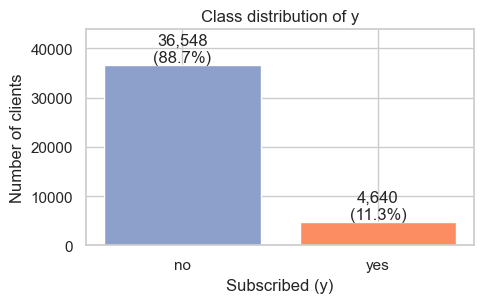

In [164]:

counts = bank['y'].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(counts.index, counts.values, color=["#8da0cb", "#fc8d62"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set(title="Class distribution of y", xlabel="Subscribed (y)", ylabel="Number of clients", ylim=(0, counts.max() * 1.2))
plt.tight_layout(); plt.show()


**Explanation**

Only **4,640 of 41,188 clients (11.3%)** subscribed. This **class imbalance** matters in three ways:
1. A model that always predicts "no" is already **88.7% accurate** but useless. That is why we need a **majority-class baseline**, and why we judge models with **ROC-AUC and PR-AUC**, not accuracy.
2. The train/test split must be **stratified**, so both parts keep 11.3% "yes".
3. The default cut-off of 0.5 is not suitable, so a **decision threshold** must be chosen deliberately later.

## Hidden missing values.

In [165]:

y_bin = (bank['y'] == 'yes').astype(int)   # 1 = subscribed, 0 = not

rows = []
for col in bank.select_dtypes(exclude='number').columns.drop('y'):
    unk = bank[col] == 'unknown'
    if unk.any():
        rows.append({'column': col,
                     'n_unknown': int(unk.sum()),
                     '% unknown': round(100 * unk.mean(), 1),
                     'subscription rate if unknown': round(y_bin[unk].mean(), 3),
                     'subscription rate if known': round(y_bin[~unk].mean(), 3)})
pd.DataFrame(rows).set_index('column')

,n_unknown,% unknown,subscription rate if unknown,subscription rate if known
column,,,,
job,330,0.8,0.112,0.113
marital,80,0.2,0.150,0.113
education,1731,4.2,0.145,0.111
default,8597,20.9,0.052,0.129
housing,990,2.4,0.108,0.113
loan,990,2.4,0.108,0.113



**Explanation**
- Six columns contain `"unknown"`. The biggest is **`default`**, with about **21% unknown**. `default = "yes"` appears only 3 times, so this column is really "no" vs "unknown".
- Clients with `default = unknown` subscribe at about **5%**, against about **13%** for the others. The missingness **carries information**.
- **Implication for Step 4:** deleting these rows would lose a lot of data and bias the sample. Replacing "unknown" with the most common value would hide a real signal. So we will **keep "unknown" as its own category**.

## Numeric attributes by class: histograms


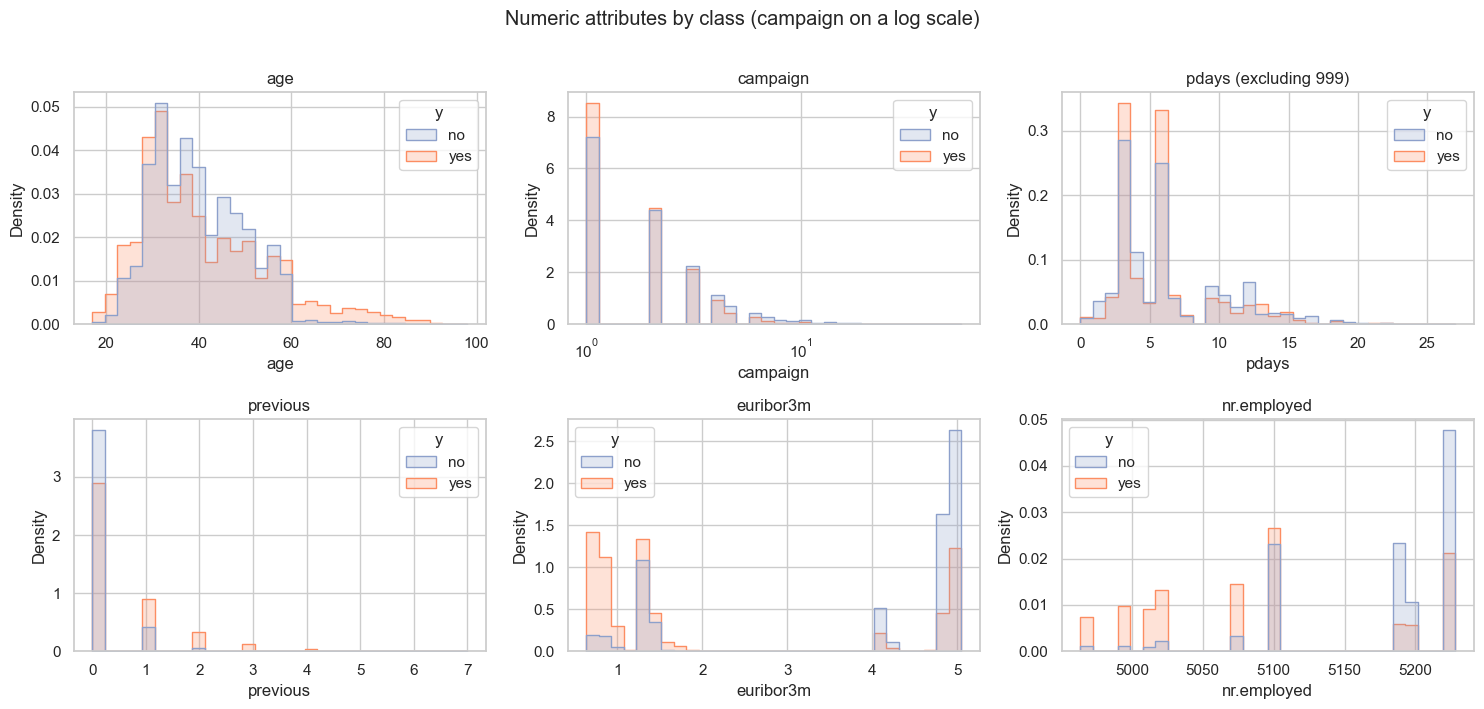

Share of rows with pdays = 999 (never contacted before): 96.3%


In [166]:

num_cols = ['age', 'campaign', 'pdays', 'previous', 'euribor3m', 'nr.employed']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), num_cols):
    d = bank[[col, 'y']]
    title = col
    if col == 'pdays':                      # leave out the 999 code so the real values are visible
        d = d[d['pdays'] != 999]; title = 'pdays (excluding 999)'
    sns.histplot(data=d, x=col, hue='y', stat='density', common_norm=False, bins=30,
                 element='step', log_scale=(col == 'campaign'), ax=ax, palette=["#8da0cb", "#fc8d62"])
    ax.set_title(title)
plt.suptitle('Numeric attributes by class (campaign on a log scale)', y=1.01)
plt.tight_layout(); plt.show()

print("Share of rows with pdays = 999 (never contacted before): {:.1%}".format((bank['pdays'] == 999).mean()))


**Explanation**
- **`age`**: subscribers include more very young (< 25) and older (> 60) clients. The relationship is **not a straight line**, which supports trying non-linear models such as decision trees.
- **`campaign`**: subscribers are concentrated at 1–3 calls. Calling the same person many times rarely works. The long right tail (up to 56 calls) contains **extreme values**, which Step 4 checks as possible outliers.
- **`pdays`**: about **96%** of rows are 999 ("never contacted"). Clients who *were* contacted before subscribe much more often, so Step 4 turns this into a **"previously contacted" flag**.
- **`euribor3m` and `nr.employed`** (economic indicators): "yes" is concentrated at **low interest rates and low employment**. The economic situation at the time of the call strongly affects subscription.

## Categorical attributes: subscription rate for each value

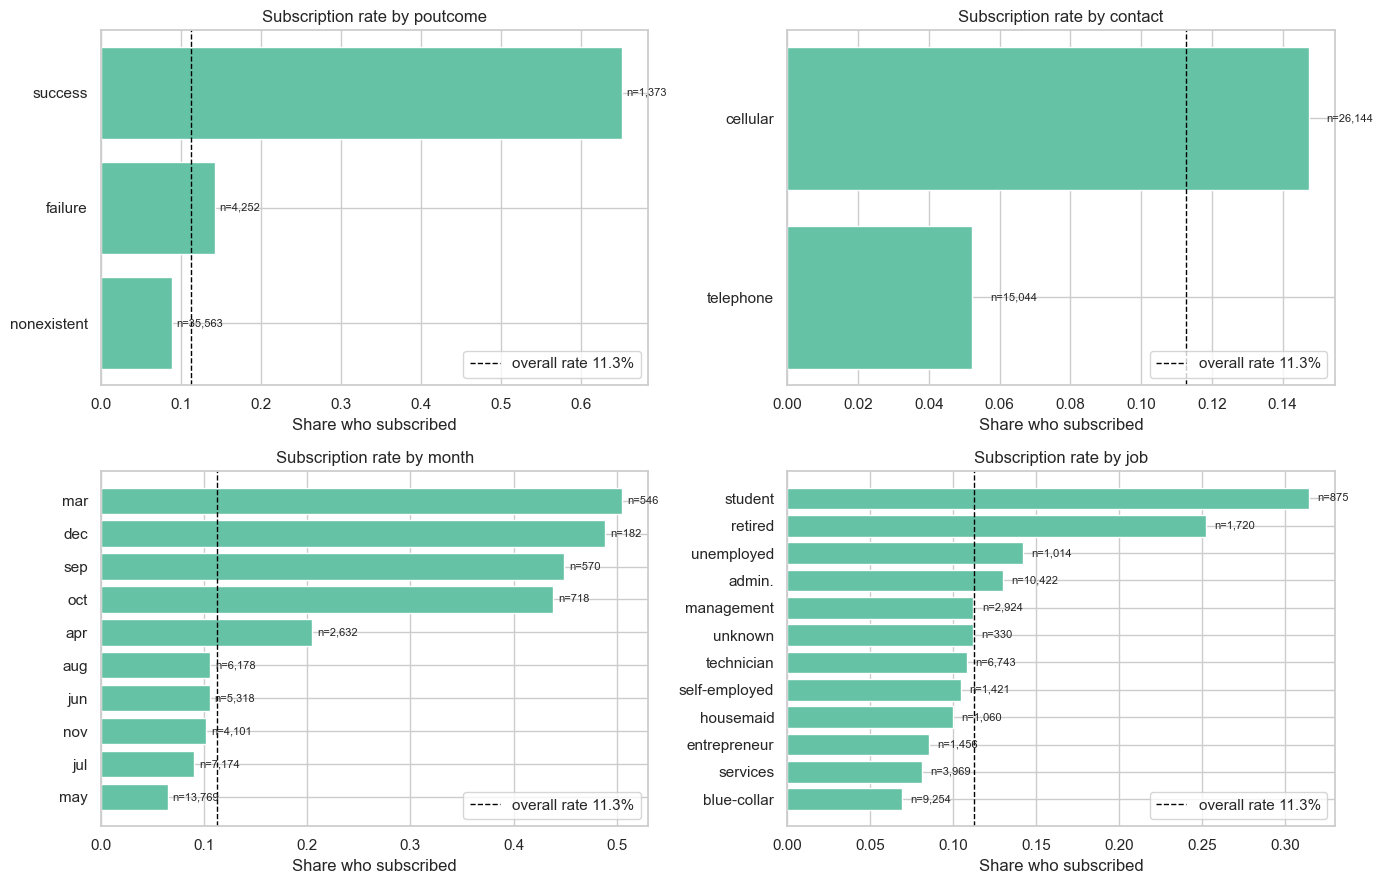

y,no,yes,All
poutcome,,,
failure,3647,605,4252
nonexistent,32422,3141,35563
success,479,894,1373
All,36548,4640,41188


In [167]:

cat_cols = ['poutcome', 'contact', 'month', 'job']
overall = y_bin.mean()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = y_bin.groupby(bank[col]).agg(['mean', 'count']).sort_values('mean')
    ax.barh(rate.index.astype(str), rate['mean'], color='#66c2a5')
    ax.axvline(overall, ls='--', color='black', lw=1, label=f'overall rate {overall:.1%}')
    for i, (r, n) in enumerate(zip(rate['mean'], rate['count'])):
        ax.text(r + 0.005, i, f'n={n:,}', va='center', fontsize=8)
    ax.set(title=f'Subscription rate by {col}', xlabel='Share who subscribed'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

pd.crosstab(bank['poutcome'], bank['y'], margins=True)


**Explanation**
- **`poutcome = success`**: about **65%** of clients who subscribed in a *previous* campaign subscribe again. It is the strongest single signal, though only about 3% of clients have it.
- **`contact`**: clients called on a **mobile (cellular)** subscribe at about **15%**, against about **5%** on a landline.
- **`month`**: March, September, October and December have rates near **45–50%** but very few calls. **May** has the most calls and the lowest rate (about 6%). This reflects how the bank scheduled its campaigns.
- **`job`**: **students and retirees** have the highest rates, consistent with the age histogram.
- **Implication:** several attributes clearly help to predict `y`. They are categorical, so Step 4 will **one-hot encode** them.

## Correlation between numeric attributes


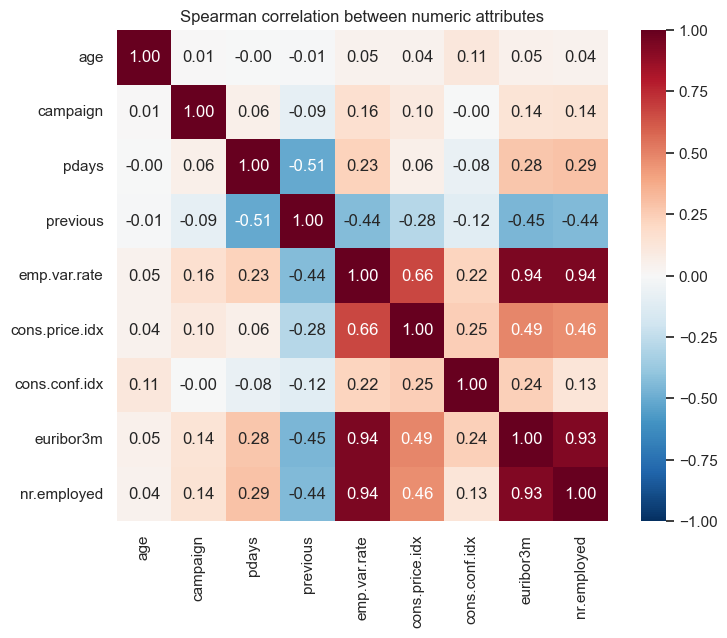

In [168]:

corr = bank[['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx',
             'cons.conf.idx', 'euribor3m', 'nr.employed']].corr(method='spearman')
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True)
plt.title('Spearman correlation between numeric attributes')
plt.tight_layout(); plt.show()


**Explanation.** 
The economic indicators **`emp.var.rate`, `euribor3m` and `nr.employed` are almost perfectly correlated** (ρ > 0.9): they all measure the same economic cycle. Correlated attributes make the individual coefficients of a linear model (logistic regression) unstable and hard to interpret (Regression tutorial §5.3). **Implication:** use **regularised** logistic regression, and interpret these attributes as a group, not one by one. Tree-based models are not harmed in their predictions.

## Two checks that shape the whole project: leakage and time

In [169]:

from sklearn.metrics import roc_auc_score

# (a) Leakage: how well does call duration alone separate yes from no?
print(f"ROC-AUC of `duration` on its own: {roc_auc_score(y_bin, bank['duration']):.3f}")

# (b) Time: the rows are in date order (May 2008 -> Nov 2010). Subscription rate in each fifth of the file:
fifths = pd.qcut(np.arange(len(bank)), 5, labels=['1st fifth', '2nd', '3rd', '4th', 'last fifth'])
print("\nSubscription rate by chronological fifth of the data:")
print(y_bin.groupby(fifths, observed=True).mean().round(3).to_string())

ROC-AUC of `duration` on its own: 0.818

Subscription rate by chronological fifth of the data:
1st fifth     0.031
2nd           0.054
3rd           0.059
4th           0.111
last fifth    0.308



**Explanation**
- **(a) Leakage.** `duration` *alone* separates subscribers from non-subscribers with ROC-AUC ≈ **0.82**. That is only possible because a long call happens *because* the client is interested, and it is known only **after** the call. A model that uses it could not be used to decide whom to call. **Decision: `duration` is excluded from all models.**
- **(b) Change over time.** The subscription rate rises from about **3%** in the earliest records to about **31%** in the latest, during the 2008–2010 financial crisis. The economic attributes therefore act like a "clock". A model trained on these years may not transfer directly to future campaigns. This is a **limitation** to discuss, and a reason to check the model's predictions over time.

## Summary of the exploration

| Finding | Evidence | What we will do (Step 4 onwards) |
|---|---|---|
| Imbalanced class label | 11.3% "yes" | Majority-class baseline; ROC-AUC / PR-AUC; stratified split; tune the threshold |
| `pdays = 999` is a code | 96% of rows | Create a "previously contacted" flag; recode 999 |
| Hidden missing values | `"unknown"` in 6 columns (21% in `default`), and informative | Keep "unknown" as its own category |
| Skewed counts / extreme values | `campaign` up to 56, `previous` up to 7 | Check outliers (Z-score); log-transform for logistic regression |
| Non-linear patterns | U-shaped age effect; strong categorical effects | Compare a linear model with tree-based models; one-hot encode categoricals |
| Correlated economic indicators | ρ > 0.9 | Regularise; interpret as a group |
| Leakage | `duration` ROC-AUC 0.82 on its own | Drop `duration` |
| Drift over time | 3% → 31% subscription rate | Discuss as a limitation; check robustness |


## Data Preparation
This is involves cleaning and transformation with justification and including finding missing values,outliers, duplicates,sampling and discretisation.

* We deal with each data-quality issue found above, compare the options, and justify each decision with evidence.

In [170]:

# Missing values.
tmp = bank.replace('unknown', np.nan)
dropped = tmp.dropna()
print("Rows in original data          = %d" % len(bank))
print("Rows after dropping 'unknown'  = %d  (%.1f%% of the data lost)" % (len(dropped), 100 * (1 - len(dropped) / len(bank))))
print("Subscription rate: original %.3f  vs  after dropna %.3f" % (y_bin.mean(), (dropped['y'] == 'yes').mean()))

Rows in original data          = 41188
Rows after dropping 'unknown'  = 30488  (26.0% of the data lost)
Subscription rate: original 0.113  vs  after dropna 0.127



**Decision: keep `"unknown"` as its own category.**
- **Dropping** the rows would lose about **26%** of the data and change the subscription rate from 11.3% to about 12.7%. The remaining sample would be **biased**.
- **Filling in** the most common value would merge `default = unknown` clients, who subscribe at **5%**, with `default = no` clients (13%). That would hide a real signal (Step 3.3).
- Keeping "unknown" as its own category keeps all the rows and lets the models use the information.

## Outliers (Z-score method)

In [171]:

num_model = ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Z = (bank[num_model] - bank[num_model].mean()) / bank[num_model].std()
print("Values with |Z| > 3 per attribute:\n", (Z.abs() > 3).sum().to_string())
out = (Z.abs() > 3).any(axis=1)
print("\nRows with at least one |Z| > 3: %d (%.1f%%)" % (out.sum(), 100 * out.mean()))
print("Subscription rate in those rows: %.3f  (overall %.3f)" % (y_bin[out].mean(), y_bin.mean()))

Values with |Z| > 3 per attribute:
 age                369
campaign           869
previous          1064
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0

Rows with at least one |Z| > 3: 2235 (5.4%)
Subscription rate in those rows: 0.314  (overall 0.113)



**Decision: keep the outliers.** **2,235 rows (5.4%)** have an extreme value, mostly from `previous`, `campaign` and `age`. They are **real behaviour**, not errors: an 85-year-old client, or a client called 20 times. They are also **informative**: these rows subscribe at **31%**, almost three times the average of 11.3%. Deleting them would bias the model. Instead we reduce their influence: logistic regression gets `log(1 + x)` of `campaign` and `previous`, and decision trees and random forests are naturally robust to extreme values because they only use the order of values.

## Duplicates

In [172]:

print("Number of duplicate rows = %d" % bank.duplicated().sum())
df = bank.drop_duplicates().reset_index(drop=True)
print("Rows before = %d, rows after removing duplicates = %d" % (len(bank), len(df)))

Number of duplicate rows = 12
Rows before = 41188, rows after removing duplicates = 41176



**Decision: remove the 12 exact duplicates.** A duplicate that ended up in both the training and the test set would let the model "recognise" a test row, which would make the results look better than they are.

##  Feature selection and transformation
| Action | Applied to | Justification |
|---|---|---|
| **Drop** | `duration` | Known only after the call: **target leakage** (ROC-AUC 0.82 on its own) |
| New flag `prev_contacted` = (pdays ≠ 999); recode 999 → −1 | `pdays` | Keeps "never contacted" as information without the false meaning "999 days" |
| **One-hot encoding** | 10 categorical columns | Models need numbers; categories have no order |
| `log(1 + x)` + **standardisation** | numeric columns (logistic regression only) | Reduces skew; regularisation needs features on the same scale. Trees need neither |

All learned transformations (scaling, encoding) sit inside a scikit-learn **`Pipeline`**, so they are fitted on the training data only and nothing leaks from the test data.

In [173]:

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

def prepare(frame):
    X = frame.drop(columns=['y', 'duration']).copy()        # drop the label and the leaky column
    y = (frame['y'] == 'yes').astype(int)
    X['prev_contacted'] = (X['pdays'] != 999).astype(int)
    X['pdays'] = X['pdays'].where(X['pdays'] != 999, -1)
    return X, y

X_all, y_all = prepare(df)
CAT = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
NUM = ['age', 'campaign', 'pdays', 'previous', 'prev_contacted',
       'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

def make_preprocessor(kind):
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    if kind == 'linear':
        skewed = ['campaign', 'previous']
        return ColumnTransformer([
            ('log_scale', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                                    ('sc', StandardScaler())]), skewed),
            ('scale', StandardScaler(), [c for c in NUM if c not in skewed]),
            ('ohe', ohe, CAT)])
    return ColumnTransformer([('num', 'passthrough', NUM), ('ohe', ohe, CAT)])

print("Predictors used:", X_all.shape[1], "(duration removed, prev_contacted added)")


Predictors used: 20 (duration removed, prev_contacted added)



### Sampling: stratified train/test split
 We keep **20%** as a test set, **stratified** so both parts have 11.3% "yes". The test set is not touched until Step 9. All tuning and comparison uses **cross-validation on the training set**.

In [174]:

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print(f"Training set: {len(X_train):,} rows, subscription rate {y_train.mean():.4f}")
print(f"Test set:     {len(X_test):,} rows, subscription rate {y_test.mean():.4f}")

Training set: 32,940 rows, subscription rate 0.1127
Test set:     8,236 rows, subscription rate 0.1127



### SHORT DATA REPORT 

| Aspect | Finding | Decision |
|---|---|---|
| Size & type | 41,188 records; 20 predictors (10 numeric, 10 categorical); binary label `y` | Large enough for flexible models and cross-validation |
| Class balance | 11.27% "yes": imbalanced | Majority-class baseline; ROC-AUC / PR-AUC; stratified split; tuned threshold |
| Leakage | `duration` known only after the call (ROC-AUC 0.82 alone) | Dropped |
| Missing values | No NaNs; `"unknown"` in 6 columns (`default` 20.9%), informative | Kept as its own category (dropping loses 26% and biases the sample) |
| Outliers | ≈5% of rows have \|Z\| > 3; genuine behaviour | Kept; log-transform for logistic regression |
| Duplicates | 12 exact duplicates | Removed |
| Sentinel value | `pdays = 999` in 96% of rows | `prev_contacted` flag + recode |
| Patterns | U-shaped age; strong effects of `poutcome`, `contact`, `month` | Compare linear and non-linear models; one-hot encoding |
| Correlation | Economic indicators ρ > 0.9 | Regularise; interpret as a group |
| Time | Rows in date order; rate rises 3% → 31% | Forward-in-time check; re-calibrate before use |

**Limitations of the data:** one bank in one unusual economic period (2008–2010), no client ID, and only the clients the bank chose to call.




## Majority-class baseline and evaluation metrics

Because only 11.3% say "yes", **accuracy is misleading**. We report:
- **PR-AUC (average precision), the main metric:** how precise the model is across all levels of recall. A useless model scores the prevalence, 0.113.
- **ROC-AUC:** the probability that a random subscriber is scored above a random non-subscriber. Useless = 0.5.
- **Lift @ top 10%:** how many times more subscribers there are among the top 10% of scores than in a random 10%.
- **Precision / recall / F1**, once a threshold is chosen.

The **majority-class baseline** always predicts the most common class, "no".

In [175]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)

def lift_at(y_true, scores, frac=0.10):
    n = int(round(frac * len(scores)))
    top = np.argsort(-np.asarray(scores))[:n]
    return np.asarray(y_true)[top].mean() / np.mean(y_true)

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred), 'f1': f1_score(y_true, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_true, proba), 'pr_auc': average_precision_score(y_true, proba),
            'lift@10%': lift_at(y_true, proba), 'brier': brier_score_loss(y_true, proba)}

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(classification_report(y_test, baseline.predict(X_test), target_names=['no', 'yes'], zero_division=0))
pd.DataFrame({'Majority-class baseline (test set)': evaluate(y_test, baseline.predict_proba(X_test)[:, 1])}).T.round(4)

              precision    recall  f1-score   support

          no       0.89      1.00      0.94      7308
         yes       0.00      0.00      0.00       928

    accuracy                           0.89      8236
   macro avg       0.44      0.50      0.47      8236
weighted avg       0.79      0.89      0.83      8236



,accuracy,precision,recall,f1,roc_auc,pr_auc,lift@10%,brier
Majority-class baseline (test set),0.8873,0.0,0.0,0.0,0.5,0.1127,1.0771,0.1127



**What the baseline shows.**
 Always predicting "no" is **88.7% accurate** but has **recall = 0**: it finds **no subscribers at all**. Its ROC-AUC is **0.50**, PR-AUC **0.113** and lift **≈1.0**. These are the numbers every model must beat, and they show why accuracy cannot be the measure of success here.



## Choosing the modelling approaches (at most three)

We list the main classification methods and pick three that suit this data and explain why the others were not chosen.

| Method | Chosen? | Reason |
|---|---|---|
| **Logistic regression** (linear, global, probabilistic) | ✅ **A** | Standard model for a yes/no outcome; gives probabilities directly; interpretable; the linear benchmark |
| **Decision tree** (non-linear, local, rule-based) | ✅ **B** | Captures non-linear effects (U-shaped age) and interactions; produces readable if–then rules |
| **Random forest** (ensemble of trees) | ✅ **C** | Averages many different trees, which removes much of a single tree's overfitting; usually very strong on tabular data |
| k-nearest neighbours | ❌ | Distances are not meaningful across 60+ one-hot columns; slow to predict for 33,000 training rows |
| Naive Bayes | ❌ | Assumes attributes are independent given the class, but the economic indicators are almost perfectly correlated |
| Support vector machine | ❌ | Training time grows quickly with 33,000 rows; no direct probabilities (needed for the threshold) |
| Gradient boosting | Considered, not ranked | A strong ensemble, but the limit is three approaches. The chosen three span linear → single tree → ensemble. Boosting is tested as a **robustness check in Step 10.3** |

The three models form a ladder of complexity: **linear → one tree → many trees**. Comparing them shows whether the relationships are non-linear, and whether averaging fixes a single tree's overfitting.


---
## Training and tuning the three models (induction)

 Each model has a complexity setting. As complexity grows, the **training** score keeps improving, but the score on **unseen** data eventually gets worse. That is overfitting. We plot both, in the tutorial's style (red = training, blue dashed = validation). "Unseen" here means the **validation folds of 5-fold cross-validation on the training set**: unlike the tutorial, we do not use the test set to choose settings, because that would make the test score optimistic.

In [176]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def curve(make_model, values):
    tr, va = [], []
    for v in values:
        r = cross_validate(make_model(v), X_train, y_train, cv=cv5, scoring='average_precision', return_train_score=True)
        tr.append(r['train_score'].mean()); va.append(r['test_score'].mean())
    return np.array(tr), np.array(va)


### Logistic regression: regularisation strength C (smaller C = simpler model)

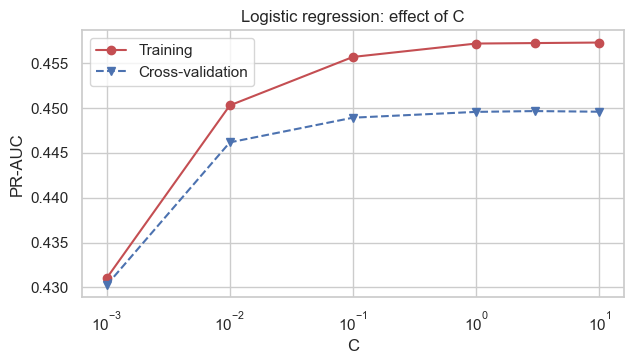

CV PR-AUC by C: {0.001: np.float64(0.4302), 0.01: np.float64(0.4462), 0.1: np.float64(0.4489), 1: np.float64(0.4496), 3: np.float64(0.4497), 10: np.float64(0.4496)} | selected C = 3


In [177]:

C_values = [0.001, 0.01, 0.1, 1, 3, 10]
make_lr = lambda C: Pipeline([('prep', make_preprocessor('linear')), ('clf', LogisticRegression(C=C, max_iter=5000))])
lr_tr, lr_va = curve(make_lr, C_values)
plt.figure(figsize=(6.5, 3.8))
plt.plot(C_values, lr_tr, 'ro-', C_values, lr_va, 'bv--'); plt.xscale('log')
plt.xlabel('C'); plt.ylabel('PR-AUC'); plt.legend(['Training', 'Cross-validation']); plt.title('Logistic regression: effect of C')
plt.tight_layout(); plt.show()
best_C = C_values[int(np.argmax(lr_va))]
print("CV PR-AUC by C:", dict(zip(C_values, np.round(lr_va, 4))), "| selected C =", best_C)


**Interpretation.** Very strong regularisation (C = 0.001) **underfits**. From about C = 0.1 the curve is flat, and training and validation stay close together. Logistic regression is a simple model, so it barely overfits. Its limit is that it can only draw a linear boundary.




### Decision tree: maximum depth (the overfitting curve)

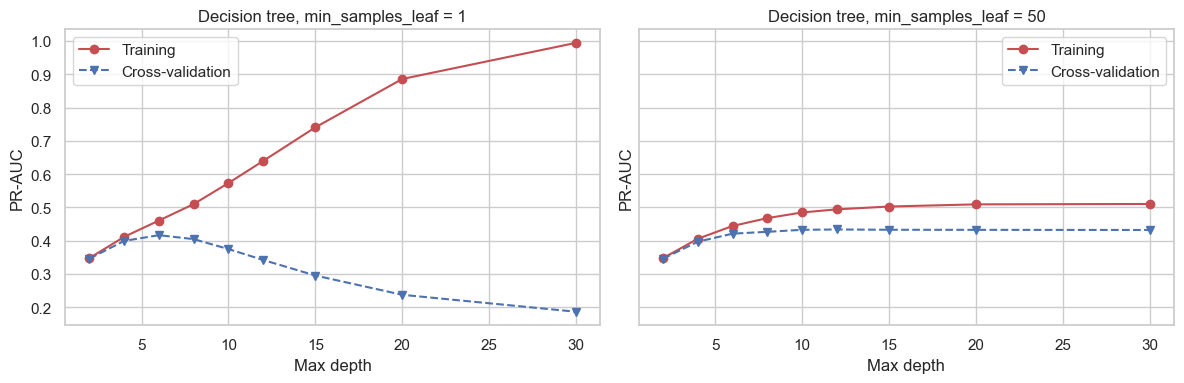

CV PR-AUC, leaf=1 : {2: np.float64(0.346), 4: np.float64(0.399), 6: np.float64(0.417), 8: np.float64(0.405), 10: np.float64(0.375), 12: np.float64(0.342), 15: np.float64(0.295), 20: np.float64(0.237), 30: np.float64(0.187)}
CV PR-AUC, leaf=50: {2: np.float64(0.346), 4: np.float64(0.397), 6: np.float64(0.421), 8: np.float64(0.427), 10: np.float64(0.433), 12: np.float64(0.434), 15: np.float64(0.433), 20: np.float64(0.433), 30: np.float64(0.432)}
Selected: max_depth = 12, min_samples_leaf = 50


In [178]:

depths = [2, 4, 6, 8, 10, 12, 15, 20, 30]
make_tree = lambda leaf: (lambda d: Pipeline([('prep', make_preprocessor('tree')),
                                              ('clf', DecisionTreeClassifier(criterion='entropy', max_depth=d,
                                                                             min_samples_leaf=leaf, random_state=SEED))]))
dt = {leaf: curve(make_tree(leaf), depths) for leaf in [1, 50]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, leaf in zip(axes, [1, 50]):
    ax.plot(depths, dt[leaf][0], 'ro-', depths, dt[leaf][1], 'bv--')
    ax.set(xlabel='Max depth', ylabel='PR-AUC', title=f'Decision tree, min_samples_leaf = {leaf}'); ax.legend(['Training', 'Cross-validation'])
plt.tight_layout(); plt.show()
best_leaf, best_depth = max(((l, d) for l in [1, 50] for d in depths), key=lambda t: dt[t[0]][1][depths.index(t[1])])
print("CV PR-AUC, leaf=1 :", dict(zip(depths, np.round(dt[1][1], 3))))
print("CV PR-AUC, leaf=50:", dict(zip(depths, np.round(dt[50][1], 3))))
print(f"Selected: max_depth = {best_depth}, min_samples_leaf = {best_leaf}")


**Interpretation: the overfitting pattern from the tutorial.** 
With the default `min_samples_leaf = 1` (left), **training PR-AUC climbs towards 1.0** as the tree memorises the training rows. **Validation PR-AUC peaks around depth 6 (≈0.42) and then collapses** to about 0.19 at depth 30. Requiring at least **50 rows per leaf** (right) prevents the collapse, and validation PR-AUC levels off at about 0.43. We select **depth 12 with 50-row leaves**.

The top of the tree can be read as **if–then rules** (Lecture 2, rule-based classification):

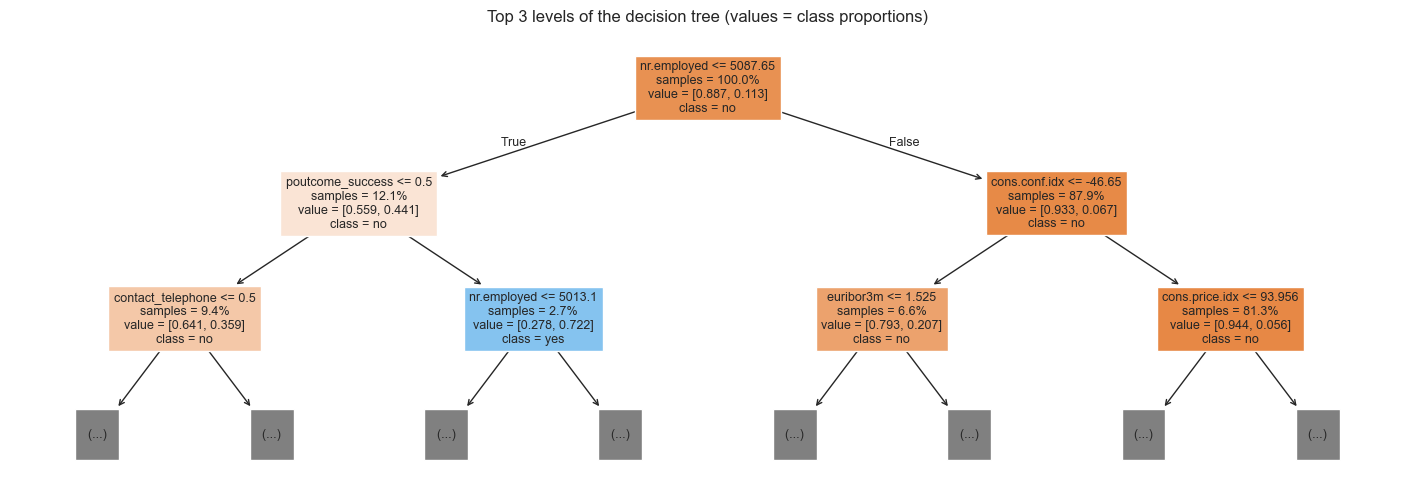

|--- nr.employed <= 5087.65
|   |--- poutcome_success <= 0.50
|   |   |--- contact_telephone <= 0.50
|   |   |   |--- truncated branch of depth 10
|   |   |--- contact_telephone >  0.50
|   |   |   |--- truncated branch of depth 5
|   |--- poutcome_success >  0.50
|   |   |--- nr.employed <= 5013.10
|   |   |   |--- truncated branch of depth 6
|   |   |--- nr.employed >  5013.10
|   |   |   |--- truncated branch of depth 4
|--- nr.employed >  5087.65
|   |--- cons.conf.idx <= -46.65
|   |   |--- euribor3m <= 1.53
|   |   |   |--- truncated branch of depth 10
|   |   |--- euribor3m >  1.53
|   |   |   |--- truncated branch of depth 3
|   |--- cons.conf.idx >  -46.65
|   |   |--- cons.price.idx <= 93.96
|   |   |   |--- truncated branch of depth 10
|   |   |--- cons.price.idx >  93.96
|   |   |   |--- truncated branch of depth 10



In [179]:

tree_model = make_tree(best_leaf)(best_depth).fit(X_train, y_train)
names = [n.split('__', 1)[1] for n in tree_model.named_steps['prep'].get_feature_names_out()]
plt.figure(figsize=(18, 6))
plot_tree(tree_model.named_steps['clf'], max_depth=2, feature_names=names, class_names=['no', 'yes'],
          filled=True, proportion=True, impurity=False, fontsize=9)
plt.title('Top 3 levels of the decision tree (values = class proportions)'); plt.show()
print(export_text(tree_model.named_steps['clf'], feature_names=names, max_depth=2))


**Interpretation.**
 The first split is on **`nr.employed` ≤ 5,087**, the low-employment crisis period, where about 44% subscribed, against 7% otherwise. Within that period, **`poutcome = success`** gives about 72% subscribers. The tree confirms the exploration: economic context, previous success and contact type matter most.



## Random forest: leaf size and number of attributes tried per split

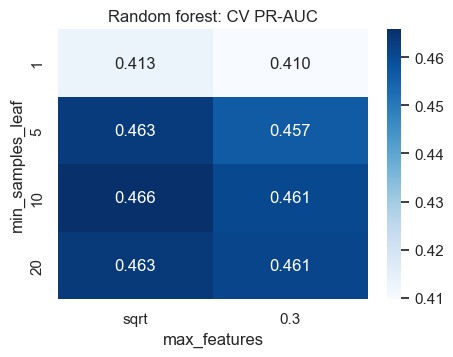

Selected: min_samples_leaf = 10, max_features = sqrt


In [180]:

rf_grid = pd.DataFrame(index=[1, 5, 10, 20], columns=['sqrt', '0.3'], dtype=float)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
for leaf in rf_grid.index:
    for mf in rf_grid.columns:
        m = Pipeline([('prep', make_preprocessor('tree')),
                      ('clf', RandomForestClassifier(n_estimators=150, min_samples_leaf=leaf,
                                                     max_features=mf if mf == 'sqrt' else float(mf), n_jobs=-1, random_state=SEED))])
        rf_grid.loc[leaf, mf] = cross_validate(m, X_train, y_train, cv=cv3, scoring='average_precision')['test_score'].mean()
plt.figure(figsize=(5, 3.5)); sns.heatmap(rf_grid, annot=True, fmt='.3f', cmap='Blues')
plt.title('Random forest: CV PR-AUC'); plt.xlabel('max_features'); plt.ylabel('min_samples_leaf'); plt.show()
best_rf_leaf, best_rf_mf = rf_grid.stack().idxmax()
best_rf_mf = best_rf_mf if best_rf_mf == 'sqrt' else float(best_rf_mf)
print(f"Selected: min_samples_leaf = {best_rf_leaf}, max_features = {best_rf_mf}")


**Interpretation.** 
Fully grown trees (leaf = 1) overfit even inside a forest. Leaves of about **10 rows** with **`max_features = 'sqrt'`** give the best validation score. Trying only a few random columns at each split makes the trees more different from one another, so averaging helps more.

In [181]:

tuned = {
    'Logistic regression': make_lr(best_C),
    'Decision tree': make_tree(best_leaf)(best_depth),
    'Random forest': Pipeline([('prep', make_preprocessor('tree')),
                               ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=int(best_rf_leaf),
                                                              max_features=best_rf_mf, n_jobs=-1, random_state=SEED))]),
}


---
## Comparing and ranking the three approaches

### Repeated cross-validation and a significance test
Each model is scored on **5-fold × 2 repeats = 10 folds**, the same folds for every model. Because the folds overlap, an ordinary t-test is too optimistic, so we use the **corrected resampled t-test**

In [183]:

from scipy import stats

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
cv_res = {n: cross_validate(m, X_train, y_train, cv=rcv, scoring={'pr': 'average_precision', 'roc': 'roc_auc', 'brier': 'neg_brier_score'})
          for n, m in tuned.items()}
cv_table = pd.DataFrame({n: {'CV PR-AUC': f"{r['test_pr'].mean():.4f} ± {r['test_pr'].std():.4f}",
                             'CV ROC-AUC': f"{r['test_roc'].mean():.4f} ± {r['test_roc'].std():.4f}",
                             'CV Brier': f"{-r['test_brier'].mean():.4f}"} for n, r in cv_res.items()}).T
display(cv_table)

def corrected_ttest(a, b, test_frac=0.2):
    d = np.asarray(a) - np.asarray(b); J = len(d)
    t = d.mean() / np.sqrt((1 / J + test_frac / (1 - test_frac)) * d.var(ddof=1))
    return d.mean(), 2 * stats.t.sf(abs(t), J - 1)

names_ = list(cv_res)
pd.DataFrame([{'comparison': f'{a} − {b}', 'PR-AUC difference': corrected_ttest(cv_res[a]['test_pr'], cv_res[b]['test_pr'])[0],
               'p (corrected)': corrected_ttest(cv_res[a]['test_pr'], cv_res[b]['test_pr'])[1]}
              for i, a in enumerate(names_) for b in names_[i + 1:]]).round(4)

,CV PR-AUC,CV ROC-AUC,CV Brier
Logistic regression,0.4499 ± 0.0114,0.7890 ± 0.0073,0.0787
Decision tree,0.4348 ± 0.0123,0.7794 ± 0.0080,0.0795
Random forest,0.4672 ± 0.0127,0.7966 ± 0.0093,0.0771


,comparison,PR-AUC difference,p (corrected)
0,Logistic regression − Decision tree,0.0150,0.0889
1,Logistic regression − Random forest,-0.0174,0.0098
2,Decision tree − Random forest,-0.0324,0.0011



### Forward-in-time check (robustness to change over time)
The rows are in date order and the subscription rate drifts strongly (Step 3.7), while a real campaign always predicts the **future**. So, inside the training set only, we train on the **earliest 80%** of rows and validate on the **latest 20%**.

In [184]:

Xc = X_train.sort_index(); yc = y_train.loc[Xc.index]; k = int(0.8 * len(Xc))
forward = {}
for n, m in tuned.items():
    p = clone(m).fit(Xc.iloc[:k], yc.iloc[:k]).predict_proba(Xc.iloc[k:])[:, 1]
    forward[n] = {'forward PR-AUC': average_precision_score(yc.iloc[k:], p), 'forward ROC-AUC': roc_auc_score(yc.iloc[k:], p)}
print(f"Earlier part rate {yc.iloc[:k].mean():.3f}  |  later part rate {yc.iloc[k:].mean():.3f}")
pd.DataFrame(forward).T.round(4)

Earlier part rate 0.065  |  later part rate 0.305


,forward PR-AUC,forward ROC-AUC
Logistic regression,0.5245,0.7466
Decision tree,0.4434,0.6605
Random forest,0.5493,0.7485



## Selection rule and ranking
The rule is fixed **before** looking at the test set: (1) the main criterion is CV PR-AUC, and models not significantly worse than the best one (corrected p ≥ 0.05) count as tied; (2) the tie-breaker is the forward-in-time PR-AUC.

In [185]:

cv_mean = {n: r['test_pr'].mean() for n, r in cv_res.items()}
top = max(cv_mean, key=cv_mean.get)
tied = [top] + [n for n in cv_mean if n != top and corrected_ttest(cv_res[top]['test_pr'], cv_res[n]['test_pr'])[1] >= 0.05]
BEST = max(tied, key=lambda n: forward[n]['forward PR-AUC'])
print("Tied for best on CV:", tied, "| Selected model:", BEST)

Tied for best on CV: ['Random forest'] | Selected model: Random forest



**Ranking (best first)**

| Rank | Model | Evidence |
|---|---|---|
| **1** | **Random forest** | Highest CV PR-AUC (**0.467 ± 0.013**) and ROC-AUC (0.797). **Significantly** better than logistic regression (difference 0.017, corrected p = 0.010) and the decision tree (0.032, p = 0.001). **Best forward-in-time PR-AUC (0.549)**. Best Brier score (0.077), so its probabilities are the most accurate |
| **2** | **Logistic regression** | Second on CV (0.450). It is ahead of the tree, though not significantly (p = 0.09), but **much more robust when predicting later data** (forward ROC-AUC 0.747 vs 0.661). It is the simplest and most interpretable model, and fits in under a second |
| **3** | **Decision tree** | Lowest CV PR-AUC (0.435) and **clearly the worst on future data** (forward ROC-AUC 0.66). A single tree splits on exact economic values (such as `nr.employed` ≤ 5,087), so it **cannot extrapolate** when the economy moves outside the training range. Its if–then rules make it useful for *explaining* the data, not as the best predictor |

**What the comparison tells us.** (1) The forest beats logistic regression, but only by about 0.02 PR-AUC, so much of the signal is captured by a linear model on well-prepared attributes. Non-linear effects add a moderate gain. (2) The forest beats the single tree on every criterion: averaging many trees fixes the overfitting seen above.



## Final evaluation on the test set (deduction)

Each tuned model is refit on the **whole training set** and applied **once** to the 8,236 test rows it has never seen.

In [186]:

from sklearn.calibration import calibration_curve

fitted = {n: clone(m).fit(X_train, y_train) for n, m in tuned.items()}
proba = {n: m.predict_proba(X_test)[:, 1] for n, m in fitted.items()}
test_table = pd.DataFrame({n: evaluate(y_test, p) for n, p in proba.items()}).T
test_table.loc['Majority baseline'] = evaluate(y_test, baseline.predict_proba(X_test)[:, 1])
display(test_table.round(4))

print(f"classification_report — {BEST} at the default threshold 0.5:")
print(classification_report(y_test, (proba[BEST] >= 0.5).astype(int), target_names=['no', 'yes']))

,accuracy,precision,recall,f1,roc_auc,pr_auc,lift@10%,brier
Logistic regression,0.8985,0.6513,0.2134,0.3214,0.8003,0.4536,4.4267,0.0779
Decision tree,0.9017,0.6705,0.2500,0.3642,0.8054,0.4714,4.6745,0.0759
Random forest,0.9002,0.6626,0.2328,0.3445,0.8085,0.4879,4.6852,0.0752
Majority baseline,0.8873,0.0000,0.0000,0.0000,0.5000,0.1127,1.0771,0.1127


classification_report — Random forest at the default threshold 0.5:
              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7308
         yes       0.66      0.23      0.34       928

    accuracy                           0.90      8236
   macro avg       0.79      0.61      0.65      8236
weighted avg       0.88      0.90      0.88      8236



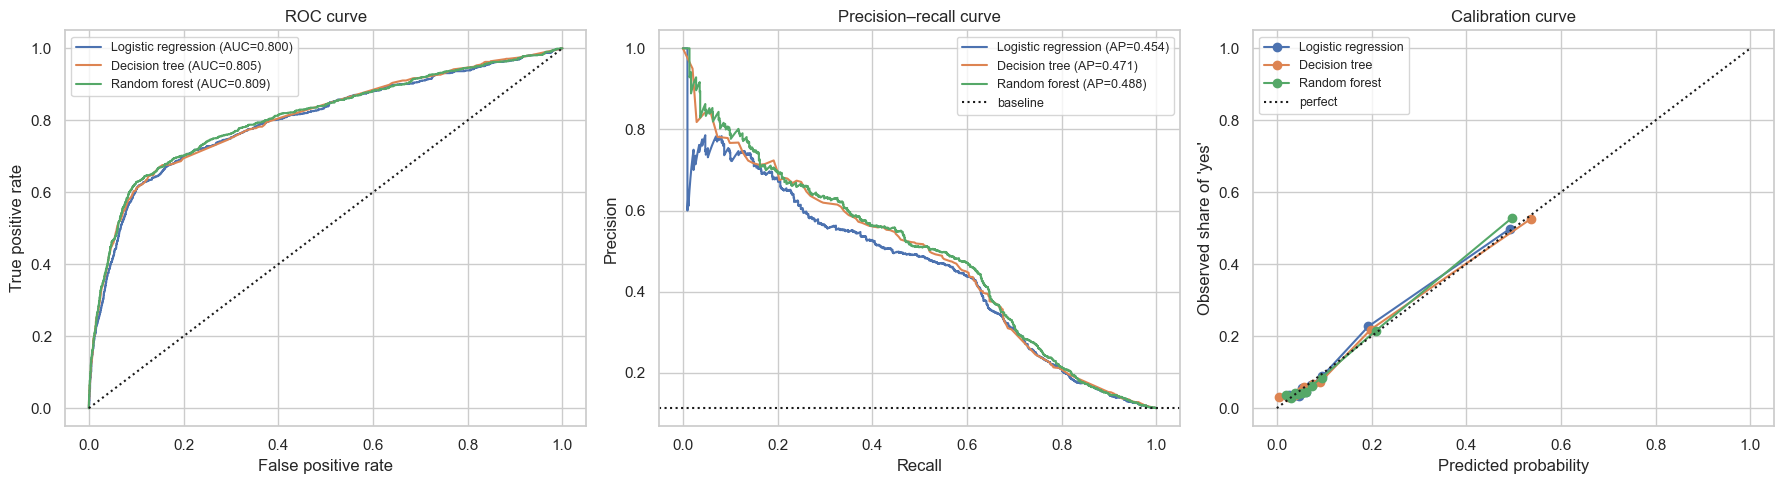

Calling the top 10% of customers by Random forest score reaches 46.9% of all subscribers
Calling the top 20% of customers by Random forest score reaches 65.9% of all subscribers
Calling the top 30% of customers by Random forest score reaches 73.5% of all subscribers


In [187]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for n, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, label=f'{n} (AUC={roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, label=f'{n} (AP={average_precision_score(y_test, p):.3f})')
    fp_, mp_ = calibration_curve(y_test, p, n_bins=10, strategy='quantile'); axes[2].plot(mp_, fp_, 'o-', label=n)
axes[0].plot([0, 1], [0, 1], 'k:'); axes[0].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_test.mean(), color='k', ls=':', label='baseline'); axes[1].set(title='Precision–recall curve', xlabel='Recall', ylabel='Precision')
axes[2].plot([0, 1], [0, 1], 'k:', label='perfect'); axes[2].set(title='Calibration curve', xlabel='Predicted probability', ylabel="Observed share of 'yes'")
for ax in axes: ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

order = np.argsort(-proba[BEST]); gains = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
for frac in [0.1, 0.2, 0.3]:
    print(f"Calling the top {frac:.0%} of customers by {BEST} score reaches {gains[int(frac * len(gains)) - 1]:.1%} of all subscribers")


**What the test set shows**
- **All three models beat the majority-class baseline by a wide margin.** The random forest reaches **ROC-AUC 0.809** and **PR-AUC 0.488**, more than 4 times the baseline's 0.113. Its **lift in the top 10% is 4.7**: the best-scored tenth of customers subscribe at 4.7 times the average rate.
- **The random forest is best on the test set too.** The decision tree edges out logistic regression here (PR-AUC 0.471 vs 0.454). The difference is small, and the cross-validation and forward-in-time evidence (Step 8) placed logistic regression second. **We do not re-rank using the test set**, because that would turn it into another tuning set.
- **Calibration:** the calibration curves lie close to the diagonal, so the predicted probabilities can be trusted as probabilities. The cost-based threshold in Step 12 relies on this.
- **Accuracy is misleading again.** The forest is only about 1.3 points more *accurate* than the baseline (90.0% vs 88.7%) but far more *useful*. At the default threshold of 0.5 it finds only **23%** of subscribers (recall 0.23), so the threshold must be lowered (Step 12).
- **Business view:** calling the top **10%** of customers reaches **47%** of all subscribers, and the top **20%** reaches **66%**. Random calling would reach 10% and 20%.



## Robustness (sensitivity) checks

###  What if we had kept `duration`? (leakage benchmark)

In [188]:

leaky = clone(tuned[BEST]).set_params(prep=ColumnTransformer([('num', 'passthrough', NUM + ['duration']),
                                                              ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)]))
dur = df['duration']
leaky.fit(X_train.assign(duration=dur.loc[X_train.index]), y_train)
p_leak = leaky.predict_proba(X_test.assign(duration=dur.loc[X_test.index]))[:, 1]
pd.DataFrame({'Random forest, realistic (no duration)': evaluate(y_test, proba[BEST]),
              'Random forest + duration (LEAKY)': evaluate(y_test, p_leak)}).T[['roc_auc', 'pr_auc']].round(3)

,roc_auc,pr_auc
"Random forest, realistic (no duration)",0.809,0.488
Random forest + duration (LEAKY),0.948,0.671



**Interpretation.** Adding `duration` would raise ROC-AUC from about **0.81 to 0.95**. It looks impressive but is **leakage**: call length is only known after the call, when the answer is already known. Our realistic model gives up this apparent performance so that it can be **used before the call**.




### Train on the past, test on the future (whole dataset)

In [189]:
cut = int(0.8 * len(X_all))
fut = {}
for n, m in tuned.items():
    p = clone(m).fit(X_all.iloc[:cut], y_all.iloc[:cut]).predict_proba(X_all.iloc[cut:])[:, 1]
    fut[n] = {'ROC-AUC (future)': roc_auc_score(y_all.iloc[cut:], p), 'PR-AUC (future)': average_precision_score(y_all.iloc[cut:], p),
              'mean predicted prob.': p.mean(), 'actual future rate': y_all.iloc[cut:].mean()}
pd.DataFrame(fut).T.round(3)

,ROC-AUC (future),PR-AUC (future),mean predicted prob.,actual future rate
Logistic regression,0.747,0.524,0.256,0.308
Decision tree,0.637,0.437,0.133,0.308
Random forest,0.746,0.545,0.156,0.308



**Interpretation.** Trained on the earlier 80% of records (6% "yes") and tested on the last 20% (31% "yes"), ROC-AUC drops from about 0.80 to **0.75** for the random forest and logistic regression, and to **0.64** for the decision tree. This confirms the ranking. The forest still **ranks** customers usefully (PR-AUC 0.545 against a future baseline of 0.31), but its **probabilities are too low**: it predicts 16% on average when the true rate is 31%. Before each new campaign, the model should therefore be **re-calibrated on recent data** and the threshold re-checked.


### Robustness check: a quick, untuned comparison including gradient boosting
An earlier, simpler version of this analysis compared **logistic regression, random forest and gradient boosting** with default settings and `class_weight='balanced'`, and ranked them on one test-set ROC-AUC. We reproduce that set-up here with exactly its model settings, on our cleaned data, for two reasons:
1. To check whether **gradient boosting**, a fourth candidate, should have been in the top three.
2. To show how **design choices** (no tuning, class weighting, ranking on the test set, how PR-AUC is computed) change the conclusions.

In [190]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import precision_recall_curve, auc

quick_pre = ColumnTransformer([('num', StandardScaler(), NUM),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])
quick_models = {
    'Logistic Regression (balanced, untuned)': LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced'),
    'Random Forest (balanced, untuned)': RandomForestClassifier(n_estimators=100, random_state=SEED, class_weight='balanced', n_jobs=-1),
    'Gradient Boosting (default)': GradientBoostingClassifier(random_state=SEED),
}
quick_fitted, rows = {}, []
for name, model in quick_models.items():
    pipe = Pipeline([('pre', quick_pre), ('clf', model)]).fit(X_train, y_train)
    quick_fitted[name] = pipe
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    prec_v, rec_v, _ = precision_recall_curve(y_test, y_prob)
    rows.append({'Model': name, 'Precision @0.5': precision_score(y_test, y_pred), 'Recall @0.5': recall_score(y_test, y_pred),
                 'F1 @0.5': f1_score(y_test, y_pred), 'ROC-AUC': roc_auc_score(y_test, y_prob),
                 'PR-AUC (trapezoid auc)': auc(rec_v, prec_v), 'PR-AUC (average precision)': average_precision_score(y_test, y_prob),
                 'mean predicted prob.': y_prob.mean()})
quick_tbl = pd.DataFrame(rows).set_index('Model')
quick_tbl.loc['Random forest (our tuned model, Step 9)'] = {
    'Precision @0.5': precision_score(y_test, proba[BEST] >= 0.5), 'Recall @0.5': recall_score(y_test, proba[BEST] >= 0.5),
    'F1 @0.5': f1_score(y_test, proba[BEST] >= 0.5), 'ROC-AUC': roc_auc_score(y_test, proba[BEST]),
    'PR-AUC (trapezoid auc)': auc(*precision_recall_curve(y_test, proba[BEST])[1::-1]),
    'PR-AUC (average precision)': average_precision_score(y_test, proba[BEST]), 'mean predicted prob.': proba[BEST].mean()}
print(f"Actual subscription rate in the test set: {y_test.mean():.3f}")
quick_tbl.round(4)

Actual subscription rate in the test set: 0.113


,Precision @0.5,Recall @0.5,F1 @0.5,ROC-AUC,PR-AUC (trapezoid auc),PR-AUC (average precision),mean predicted prob.
Model,,,,,,,
"Logistic Regression (balanced, untuned)",0.3595,0.6455,0.4618,0.8002,0.4452,0.4457,0.3898
"Random Forest (balanced, untuned)",0.5517,0.2877,0.3782,0.7794,0.4212,0.4182,0.1123
Gradient Boosting (default),0.6405,0.2284,0.3368,0.8074,0.4759,0.4763,0.1117
"Random forest (our tuned model, Step 9)",0.6626,0.2328,0.3445,0.8085,0.4876,0.4879,0.1119



**What this robustness check shows**

1. **Gradient boosting does not earn a place in the top three.** With default settings it is **as good as our random forest in cross-validation** (CV PR-AUC 0.464 vs 0.467; ROC-AUC 0.795 vs 0.798). It is **clearly worse at predicting later data** (forward ROC-AUC **0.69 vs 0.75**; PR-AUC 0.48 vs 0.55). Like the single decision tree, boosting relies on precise splits of the economic indicators and cannot extrapolate when the economy changes. On the evidence used in Step 8, it would not displace the random forest. Our ranking stands.
2. **Ranking on one test-set number is fragile.** On the test set alone, default gradient boosting has a higher ROC-AUC (0.807) than the *untuned* logistic regression (0.800). A ranking that used only this number would put boosting first. Cross-validation and the forward-in-time check (Step 8) give a fuller and fairer picture.
3. **Tuning matters.** The *untuned* random forest (fully grown trees) is the **worst** model here (PR-AUC 0.39), but our *tuned* forest (10-row leaves, Step 7.3) is the **best** (PR-AUC 0.49). Models must be tuned before they are ranked, otherwise the ranking reflects the default settings rather than the methods.
4. **`class_weight='balanced'` distorts the probabilities.** The balanced logistic regression predicts a mean probability of **0.39** when the true rate is **0.11**, and the balanced forest predicts 0.19. Their predictions are no longer real probabilities. They therefore look different at the 0.5 cut-off (higher recall, lower precision), but their **ranking quality (ROC-AUC) does not improve**. That is why we did **not** re-weight the classes. We handle the imbalance with the **threshold** (Step 12), which needs calibrated probabilities (mean predicted 0.112 for our forest vs 0.113 actual).
5. **How PR-AUC is computed matters a little.** The trapezoid method `auc(recall, precision)` and `average_precision_score` give similar values here (within 0.004), but the trapezoid method can overstate the area. We report average precision throughout, as scikit-learn recommends.


## Which attributes does the model rely on?

**Permutation importance:** shuffle one attribute at a time in the test set and measure how much PR-AUC drops. A large drop means the model relies on that attribute.

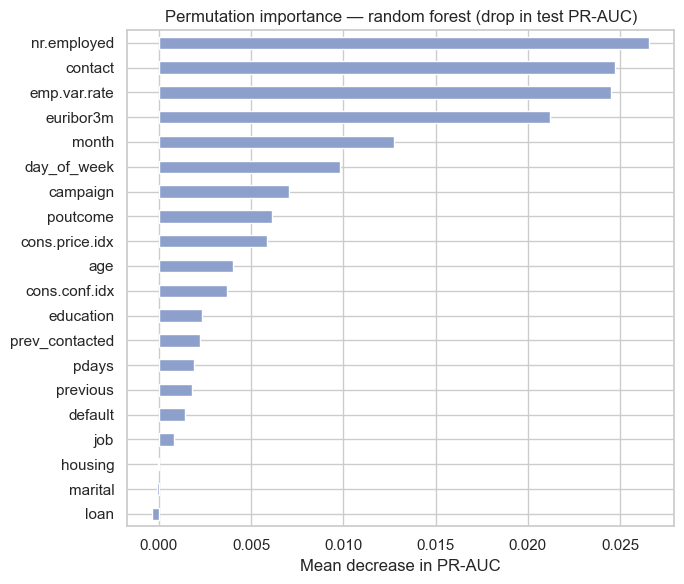

In [191]:

from sklearn.inspection import permutation_importance

perm = permutation_importance(fitted[BEST], X_test, y_test, scoring='average_precision', n_repeats=5, random_state=SEED)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(7, 6), color='#8da0cb', title='Permutation importance — random forest (drop in test PR-AUC)')
plt.xlabel('Mean decrease in PR-AUC'); plt.tight_layout(); plt.show()


**Interpretation**
- **Economic context matters most.** `nr.employed`, `emp.var.rate` and `euribor3m` are three of the four most important attributes, consistent with the exploration (Step 3.4) and with the tree's first split. People subscribed far more often in the low-interest, low-employment period. These three are highly correlated (Step 3.6), so their importance should be read **as a group**.
- **`contact`** (mobile vs landline) is the most important non-economic attribute, followed by **`month`**, **`day_of_week`**, **`campaign`** and **`poutcome`**. These describe *how and when* the campaign was run and the client's history. `day_of_week` matters more to the model than its weak overall association in Step 3 suggested, probably through interactions with month and the economic indicators.
- **`housing`, `loan` and `marital` contribute almost nothing**, matching their very weak relationship with `y` in the exploration.
- **Caution:** importance shows what the model *uses* to predict, not what *causes* subscription.


Recommending a decision threshold

**The trade-off.** The model gives each customer a probability *p*, and the bank calls everyone with *p* ≥ *t*.
- **A lower *t*** means more calls: more subscribers are reached (fewer **missed subscribers**, false negatives) but there are more **unnecessary calls** (false positives).
- **A higher *t*** means fewer, more precise calls, but more subscribers are never called.

**How we choose *t*.** If a call costs **c** and a new subscriber is worth **V**, then **profit = V × TP − c × (TP + FP)**. For well-calibrated probabilities (Step 9), the best threshold is close to **c / V** (Elkan, 2001). The bank has not given its costs, so we **assume V/c = 8**: a subscriber is worth about 8 calls (for example, a call costs about UGX 5,000 and a deposit brings about UGX 40,000 in margin). We then test other ratios. The threshold is chosen on **out-of-fold predictions for the training set**, never on the test set.

Profit-maximising threshold (V/c = 8): 0.14   (theory: c/V = 0.125)


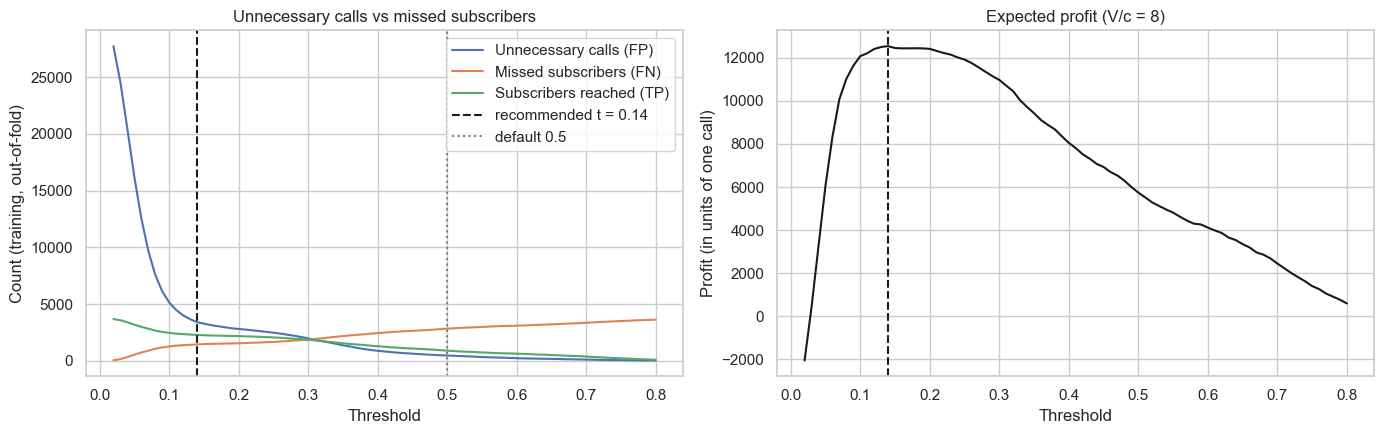

,best threshold,share called,precision,recall
V/c,,,,
3,0.32,0.105,0.503,0.468
5,0.20,0.151,0.437,0.586
8,0.14,0.172,0.401,0.614
10,0.13,0.182,0.386,0.622
15,0.07,0.381,0.225,0.762
20,0.05,0.590,0.164,0.858


In [192]:
oof = cross_val_predict(clone(tuned[BEST]), X_train, y_train, cv=cv5, method='predict_proba')[:, 1]

def threshold_table(y_true, p, value_ratio=8.0):
    y_true = np.asarray(y_true); rows = []
    for t in np.round(np.arange(0.02, 0.81, 0.01), 2):
        call = p >= t
        tp = int((call & (y_true == 1)).sum()); fp = int((call & (y_true == 0)).sum()); fn = int((~call & (y_true == 1)).sum())
        rows.append({'threshold': t, 'share called': call.mean(), 'TP': tp, 'unnecessary calls (FP)': fp,
                     'missed subscribers (FN)': fn, 'precision': tp / max(tp + fp, 1), 'recall': tp / max(tp + fn, 1),
                     'profit': value_ratio * tp - (tp + fp)})
    return pd.DataFrame(rows)

tt = threshold_table(y_train, oof)
t_best = tt.loc[tt['profit'].idxmax(), 'threshold']
print(f"Profit-maximising threshold (V/c = 8): {t_best:.2f}   (theory: c/V = {1/8:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(tt.threshold, tt['unnecessary calls (FP)'], label='Unnecessary calls (FP)')
axes[0].plot(tt.threshold, tt['missed subscribers (FN)'], label='Missed subscribers (FN)')
axes[0].plot(tt.threshold, tt['TP'], label='Subscribers reached (TP)')
axes[0].axvline(t_best, color='k', ls='--', label=f'recommended t = {t_best:.2f}'); axes[0].axvline(0.5, color='grey', ls=':', label='default 0.5')
axes[0].set(xlabel='Threshold', ylabel='Count (training, out-of-fold)', title='Unnecessary calls vs missed subscribers'); axes[0].legend()
axes[1].plot(tt.threshold, tt['profit'], color='k'); axes[1].axvline(t_best, color='k', ls='--')
axes[1].set(xlabel='Threshold', ylabel='Profit (in units of one call)', title='Expected profit (V/c = 8)')
plt.tight_layout(); plt.show()

sens = []
for ratio in [3, 5, 8, 10, 15, 20]:
    t_ = threshold_table(y_train, oof, ratio); b = t_.loc[t_['profit'].idxmax()]
    sens.append({'V/c': ratio, 'best threshold': b.threshold, 'share called': round(b['share called'], 3),
                 'precision': round(b.precision, 3), 'recall': round(b.recall, 3)})
display(pd.DataFrame(sens).set_index('V/c'))

In [193]:

def at_threshold(t):
    tn, fp, fn, tp = confusion_matrix(y_test, (proba[BEST] >= t).astype(int)).ravel()
    return {'calls made': tp + fp, 'subscribers reached (TP)': tp, 'unnecessary calls (FP)': fp,
            'missed subscribers (FN)': fn, 'precision': round(tp / (tp + fp), 3), 'recall': round(tp / (tp + fn), 3)}

pd.DataFrame({f'Recommended t = {t_best:.2f}': at_threshold(t_best), 'Default t = 0.50': at_threshold(0.5),
              'Call everyone': {'calls made': len(y_test), 'subscribers reached (TP)': int(y_test.sum()),
                                'unnecessary calls (FP)': int((y_test == 0).sum()), 'missed subscribers (FN)': 0,
                                'precision': round(y_test.mean(), 3), 'recall': 1.0}}).T

,calls made,subscribers reached (TP),unnecessary calls (FP),missed subscribers (FN),precision,recall
Recommended t = 0.14,1431.0,593.0,838.0,335.0,0.414,0.639
Default t = 0.50,326.0,216.0,110.0,712.0,0.663,0.233
Call everyone,8236.0,928.0,7308.0,0.0,0.113,1.000



### Recommendation: use a threshold of **t = 0.14** (random forest, assuming a subscriber is worth 8 calls)

**Why 0.14**
- It **maximises expected profit** on the out-of-fold training predictions, and it is close to the theoretical value c/V = 0.125. The two agree because the probabilities are well calibrated.
- On the **untouched test set** (8,236 customers), the bank would make **1,431 calls (17%)**, reach **593 of the 928 subscribers (64%)** with **41% precision**, about 3.7 times better than random calling.

**The trade-off between unnecessary calls and missed subscribers (test set)**
- Compared with **calling everyone**: 7,308 → **838 unnecessary calls**, i.e. **89% fewer wasted calls**, at the cost of missing **335 subscribers (36%)**.
- Compared with the **default threshold of 0.5**: it reaches **2.7 times more subscribers** (593 vs 216). The 1,105 extra calls bring 377 extra subscribers, which pays off whenever a subscriber is worth more than about 3 calls.

**If the bank's costs differ (sensitivity table)**
- If a subscriber is worth more (V/c = 15–20), **lower** the threshold to about 0.05–0.07: call 38–59% of customers and reach 76–86% of subscribers.
- If calls are expensive or the bank wants to avoid annoying customers (V/c = 3), **raise** it to about 0.32: call about 10% of customers with 50% precision.
- If the call centre has a **fixed capacity**, simply call customers in order of score until capacity runs out (gains figures in Step 9).

**Advice:** start with t = 0.14, replace the assumed V/c = 8 with the bank's real figures, and re-check the threshold on recent data before each campaign.


##  Responsible use, limitations and conclusions

In [194]:

grp = pd.cut(X_test['age'], [0, 25, 35, 50, 60, 120], labels=['≤25', '26–35', '36–50', '51–60', '>60'])
called = pd.Series(proba[BEST] >= t_best, index=X_test.index)
pd.DataFrame({'n': grp.value_counts().sort_index(),
              'actual subscription rate': y_test.groupby(grp, observed=True).mean(),
              'share called': called.groupby(grp, observed=True).mean(),
              'recall': called[y_test == 1].groupby(grp[y_test == 1], observed=True).mean()}).round(3)

,n,actual subscription rate,share called,recall
age,,,,
≤25,328,0.189,0.439,0.887
26–35,2953,0.124,0.182,0.605
36–50,3486,0.085,0.108,0.549
51–60,1302,0.094,0.158,0.602
>60,167,0.473,1.000,1.000



**Fairness check.** At t = 0.14, recall is similar for the working-age groups (**0.55–0.61**). It is higher for the youngest (≤25) and oldest (>60) clients, who also subscribe much more often in reality (19% and 47%). The model does not neglect any age group, but it selects **every client over 60**. The bank should make sure older customers are not over-contacted or pressured, and should check that using age or job to target financial offers is lawful (for example under Uganda's Data Protection and Privacy Act, 2019, or the EU GDPR for this Portuguese data).

**Limitations**
1. **Change over time.** The data cover one unusual period (2008–2010). Performance drops on later data and the probabilities become too low, so the model must be **re-calibrated on recent campaigns** before use.
2. **Assumed costs.** The threshold depends on V/c = 8, which we assumed. The bank should use its real figures (see the sensitivity table).
3. **Selection bias.** We only see customers the bank chose to call.
4. **No client ID.** The same person may appear in several rows.
5. **Correlation, not causation.** Importance shows what the model uses, not what *causes* subscription.

### Conclusions

1. **Exploration, report, preparation and baseline (Task 1).** The data are imbalanced (11.3% "yes") and contain a leaky attribute (`duration`, dropped), informative "unknown" values (kept), genuine outliers (kept), 12 duplicates (removed) and a 999 code (recoded). The majority-class baseline is 88.7% accurate but finds no subscribers (ROC-AUC 0.50, PR-AUC 0.113).
2. **Three approaches, ranked (Task 2):** (1) **random forest**, (2) **logistic regression**, (3) **decision tree**. The forest is significantly best in cross-validation and the most robust over time. Gradient boosting was also tested (Step 10.3): it matched the forest in cross-validation but was clearly worse on later data, so it was not ranked. On the test set it reaches ROC-AUC 0.81 and PR-AUC 0.49, and reaches two-thirds of subscribers by calling one-fifth of customers.
3. **Decision threshold (Task 3):** **t = 0.14** when a subscriber is worth about 8 calls. It cuts unnecessary calls by 89% compared with calling everyone, while reaching 64% of subscribers. The sensitivity table shows how to adjust it for other costs.
4. **Recommendation.** Use the model as a **ranking tool to support decisions**, not as an automatic gatekeeper. Pilot it on a controlled campaign, re-calibrate it regularly, and review fairness and data-protection compliance before full use.